# Aisle & Co. — Multi-Zone Data Architecture v3 (lean scope: Problems 1 and 2)
### MADT 8102 Capstone — Wedding Organizer Data Platform

**What this notebook covers**

The project scope is now two business problems only:

- **Problem 1, Seasonal demand and capacity.** Weddings bunch up in November–February
  and on auspicious dates. Are staff overloaded in peak weeks, and how much peak demand
  do we turn away?
- **Problem 2, High inquiry, low conversion.** Where do couples drop out, which channels
  and packages convert, does reply speed matter, and why do we lose them?

Marketing attribution / campaign ROI (old Problem 3) and the payment flows are out.
So this version drops the ad-platform feed, the campaign tables and every payment table
that v1 and v2 carried.

**What changed from v2**

| | v2 | v3 (this notebook) |
|---|---|---|
| Lead capture | Kiosk form + website contact form | **Chat webhooks** (LINE, Messenger, Instagram), the shared-inbox send log and the fair tablet form |
| Response time | Random number typed on the inquiry | Calculated from logged messages. The bot doesn't count. |
| Lost reason | Random pick from a list | Sales closes with a real reason, or a 30-day silence rule closes it as "No reply" |
| Other sources | Ad/social reports, payments | Staff assignments and the auspicious-date calendar |
| Simulation | — | Three years (2024–2026) driven by each couple's readiness to book (section 4) |
| Gold zone | 6 marketing/finance marts | The **6 data-warehouse tables (DW v6)** plus KPI views for Problems 1 and 2 |

The Gold zone is built with the same rules as `WeddingOrganizer_DW_v6_lean_ETL.sql`.
Section 10 shows that the two give identical results on the same data.

## 1. The five zones

| Zone | Job | What lives here |
| --- | --- | --- |
| **① Collection** | Capture data where it happens | LINE / Meta webhooks and the shared inbox, the fair tablet app (works offline), the CRM where sales log consultations, quotes, bookings and staff assignments, and the yearly auspicious-date calendar |
| **② Bronze** | Land raw data as-is, never edited | One folder per source, append-only, with ingestion metadata. **Chat message text lives here and only here**, with restricted access (Thai PDPA). |
| **③ Silver** | Clean, conform, derive | Duplicate webhooks removed, UTC converted to Bangkok time, text dropped, tracking codes parsed, response time worked out, hours spread over weeks, data-quality log |
| **④ Gold** | The warehouse | DimDate, DimPackage, DimEmployee, FactInquiry, FactEventBooking, FactEmployeeWeeklyWorkload, plus KPI views |
| **⑤ Consumption** | Where the numbers get used | Weekly ops meeting (capacity), sales review (funnel), monthly management report |

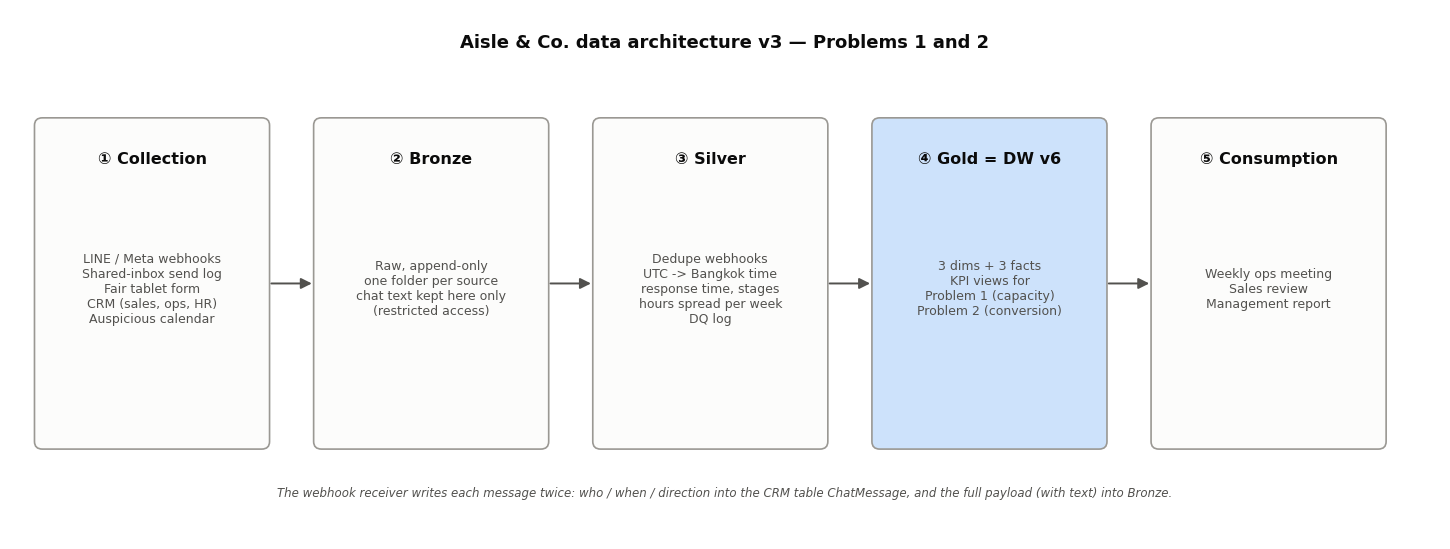

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

INK, INK2, EDGE = "#0b0b0b", "#52514e", "#9a9893"
fig, ax = plt.subplots(figsize=(14.6, 5.6))
ax.set_xlim(0, 14.6); ax.set_ylim(0, 5.6); ax.axis("off")
zones = [
    ("① Collection", "LINE / Meta webhooks\nShared-inbox send log\nFair tablet form\nCRM (sales, ops, HR)\nAuspicious calendar"),
    ("② Bronze", "Raw, append-only\none folder per source\nchat text kept here only\n(restricted access)"),
    ("③ Silver", "Dedupe webhooks\nUTC -> Bangkok time\nresponse time, stages\nhours spread per week\nDQ log"),
    ("④ Gold = DW v6", "3 dims + 3 facts\nKPI views for\nProblem 1 (capacity)\nProblem 2 (conversion)"),
    ("⑤ Consumption", "Weekly ops meeting\nSales review\nManagement report"),
]
w, h, gap, x = 2.3, 3.4, 0.55, 0.3
for i, (title, desc) in enumerate(zones):
    ax.add_patch(FancyBboxPatch((x, 1.0), w, h, boxstyle="round,pad=0.05,rounding_size=0.08",
                                linewidth=1.2, edgecolor=EDGE, facecolor="#fcfcfb" if i != 3 else "#cde2fb"))
    ax.text(x + w / 2, 1.0 + h - 0.3, title, ha="center", va="top", fontsize=11.5, fontweight="bold", color=INK)
    ax.text(x + w / 2, 1.0 + h / 2 - 0.05, desc, ha="center", va="center", fontsize=9, color=INK2)
    if i < len(zones) - 1:
        ax.add_patch(FancyArrowPatch((x + w + 0.04, 1.0 + h / 2), (x + w + gap - 0.04, 1.0 + h / 2),
                                     arrowstyle="-|>", mutation_scale=16, linewidth=1.4, color=INK2))
    x += w + gap
ax.text(7.3, 5.2, "Aisle & Co. data architecture v3 — Problems 1 and 2", ha="center", fontsize=13, fontweight="bold", color=INK)
ax.text(7.3, 0.45, "The webhook receiver writes each message twice: who / when / direction into the CRM table ChatMessage, "
        "and the full payload (with text) into Bronze.", ha="center", fontsize=8.5, color=INK2, style="italic")
plt.tight_layout(); plt.savefig("architecture_diagram_v3.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Data sources

| Source | On/offline | How it is collected | Frequency | Raw format | Bronze folder | Feeds |
|---|---|---|---|---|---|---|
| **Chat webhooks** (LINE Messaging API, Meta Messenger/Instagram) | Online | The platform POSTs every incoming message to our server: platform user ID, message ID, time (epoch ms, UTC), text. Meta also sends the ad ID for click-to-Messenger ads. LINE doesn't, so channel links and QR codes pre-type a code such as `#TIKTOK`. Platforms re-send a webhook if we don't confirm quickly, so duplicates happen. | Real time | JSON lines | `bronze/chat_webhook_events/` | P2: response time, channel |
| **Shared-inbox send log** | Online | Every reply staff send from the inbox (and every bot greeting) goes out through the platform API and is logged with the staff code. Replies typed in the LINE OA phone app are **not** logged. | Real time | JSON lines | `bronze/inbox_send_log/` | P2: response time, first responder |
| **Fair tablet form** | Offline | Staff fill a form on a tablet at the booth. It caches and syncs on reconnect; a retried sync can arrive twice. On sync, the app creates the inquiry in the CRM and gets the InquiryID back. | Batched on reconnect | JSON | `bronze/kiosk_form/` | P2: fair leads |
| **CRM extract** (the OLTP v4 lean database) | — | Nightly extract of the 12 OLTP tables minus personal data: Inquiry (stage dates, quote, status, lost reason), Event, EventEmployeeAssignment, Employee, EmployeeRole, Package, MarketingChannel, CustomerChannelAccount | Daily | CSV | `bronze/crm_*/` | P1 and P2 |
| **Auspicious-date calendar** | External | Bought or copied once a year from a published Thai astrology / Chinese calendar | Yearly | CSV | `bronze/auspicious_calendar/` | P1: peak dates |

**Not collected** (out of scope now): ad-platform spend reports, campaign tables, social
engagement, payments, vendor data, competitor prices.

**Personal data:** names, phones and emails stay in the CRM. The CRM extract leaves them
out. The kiosk form carries a phone number, which Silver uses only to check duplicates and
then hashes.

## 3. Setup

In [2]:
import pandas as pd, numpy as np, json, random, shutil, re, hashlib, math
from pathlib import Path
from datetime import date, datetime, time, timedelta, timezone

SEED = 11
random.seed(SEED); np.random.seed(SEED)
ROOT = Path("zones_v3")
if ROOT.exists():
    shutil.rmtree(ROOT)
for z in ["bronze", "silver", "gold", "oltp_snapshot"]:
    (ROOT / z).mkdir(parents=True)

YEAR_START = date(2024, 1, 1)        # three years of inquiries, 2024-2026
N_DAYS = (date(2027, 1, 1) - YEAR_START).days
AS_OF = date(2027, 1, 15)            # "today" for every status below
BKK = timezone(timedelta(hours=7))   # Asia/Bangkok, no daylight saving
OPEN_H, CLOSE_H = 9, 20              # inbox staffed 09:00-20:00; the bot answers outside
AUTO_CLOSE_DAYS = 30                 # silence rule
print("As-of date:", AS_OF)

As-of date: 2027-01-15


## 4. Collection zone — simulating three business years (2024–2026)

What happens in the business, step by step. Outcomes come from couple behaviour, not from random labels:

- A couple messages us on LINE, Facebook or Instagram, or signs up at a fair booth.
- Outside 09:00–20:00 only the bot answers. Staff reply next morning.
- 6% of staff replies are typed on a phone and never logged.
- 20% of couples delete the pre-typed TikTok/Website code, so the lead looks like plain LINE.
- Couples who stop replying are closed by the 30-day rule ("No reply").

**Behaviour assumptions.** Each couple has a hidden readiness to book, *z* (normal, sd 1). It is never stored.
The CRM only sees what readiness causes, which is what a real sales team sees too. Probabilities are
logistic: p = 1 / (1 + e^(−x)).

| Step | What drives it (x) | Visible in |
|---|---|---|
| Readiness *z* | Mean by true channel: Referral +0.6, Walk-in +0.3, LINE +0.2, Facebook/Instagram 0, Website −0.2, Fair −0.3, TikTok −0.8 | (hidden) |
| Gives a wedding date | 1.6 + 0.9 z | `RequestedEventDate` |
| Picks a package at once | 1.2 + 0.8 z | `IndicativePackageID` |
| Concrete questions in the first chat | Poisson, mean e^(−0.4 + 0.9 z), at most 4 | `ChatMessage` |
| Writes back later | Gap between messages, mean 20 h × e^(−0.9 z), at most 10 | `ChatMessage` |
| Consultation | −0.4 + 1.1 z + 0.5 if we replied < 1 h (−0.7 if > 24 h) + 0.4 if a date was given | `ConsultationDate` |
| Quote | 1.0 + 0.6 z | `QuotedDate` |
| Booking (after a quote) | −0.9 + 1.2 z + 0.5 Referral − 0.6 peak/auspicious date − 0.8 quote > 16% of budget − 0.5 wedding < 150 days away | `Event` |
| Sales closes with a reason (else "No reply") | 0.2 + 0.6 z | `LostReason` |

In 2026 a TikTok campaign makes TikTok a third of online inquiries (10% before). TikTok couples are less ready, so
2026 conversion drops. This is the drift the model monitoring has to catch.

These are assumptions for a simulation, chosen to resemble how wedding sales work. They are not
measured from a real business. A model trained on this data shows that the pipeline works; with the
real CRM, the same pipeline learns the real drivers.


In [3]:
# ---- 4.1 Reference data (CRM master tables + calendar) ----
D = date
ausp_rows = []
d = D(2023, 1, 1)
while d <= D(2028, 12, 31):
    hi = d.month in (11, 12, 1, 2)
    if random.random() < (.15 if hi else .04):
        ausp_rows.append((d, "ThaiAstrology", random.choice(["High", "Medium"])))
    if random.random() < (.06 if hi else .03):
        ausp_rows.append((d, "ChineseCalendar", random.choice(["High", "Medium", "Low"])))
    d += timedelta(1)
auspicious = pd.DataFrame(ausp_rows, columns=["CalendarDate", "DateType", "AuspiciousLevel"])
ausp_dates = set(auspicious["CalendarDate"])
def is_lent(d):  # Buddhist Lent, approximated
    return (d.month == 7 and d.day >= 20) or d.month in (8, 9) or (d.month == 10 and d.day <= 17)

channels = pd.DataFrame([(1, "LINE OA", "Online", None), (2, "Facebook", "Online", None), (3, "Instagram", "Online", None),
                         (4, "TikTok", "Online", "#TIKTOK"), (5, "Website", "Online", "#WEB"), (6, "Wedding Fair", "Offline", "#FAIR"),
                         (7, "Referral", "Offline", None), (8, "Walk-in", "Offline", None)],
                        columns=["ChannelID", "ChannelName", "ChannelType", "TrackingCode"]).assign(Status="Active")
fair_days = {D(y, m, dd) + timedelta(k) for y in (2024, 2025, 2026) for m, dd in [(1, 23), (3, 13), (6, 5), (8, 21), (10, 16)] for k in range(3)}

PK = [(1, "Full Planning", "Full", None, "Percent", 12.5, D(2023, 1, 1), D(2026, 6, 30)),
      (2, "Full Planning", "Full", None, "Percent", 13.5, D(2026, 7, 1), None),
      (3, "Partial Planning", "Partial", 90000, "Fixed", None, D(2023, 1, 1), None),
      (4, "Day-of Coordination", "DayOf", 45000, "Fixed", None, D(2023, 1, 1), D(2026, 6, 30)),
      (5, "Day-of Coordination", "DayOf", 52000, "Fixed", None, D(2026, 7, 1), None),
      (6, "Custom", "Custom", None, "Fixed", None, D(2023, 1, 1), None)]
packages = pd.DataFrame(PK, columns=["PackageID", "PackageName", "PackageType", "BasePrice", "ServiceFeeType",
                                     "ServiceFeeRate", "EffectiveFrom", "EffectiveTo"])
packages["Status"] = np.where(packages["EffectiveTo"].isna(), "Active", "Retired")
def pkg(ptype, on):  # the price version valid on a date
    return next(p for p in PK if p[2] == ptype and p[6] <= on and (p[7] is None or on <= p[7]))

roles = pd.DataFrame([(1, "Lead Planner"), (2, "Planner"), (3, "Coordinator"), (4, "Event Staff"),
                      (5, "Sales Executive"), (6, "Marketing Executive"), (7, "Finance Officer")],
                     columns=["RoleID", "RoleName"]).assign(Status="Active")
STAFF = [(1, 1, "Som", 50, 25), (2, 1, "Beam", 50, 25), (3, 1, "Ann", 48, 25), (4, 2, "Nina", 44, 20), (5, 3, "Pim", 44, 30),
         (6, 3, "Mook", 44, 30), (7, 4, "Golf", 40, 40), (8, 5, "May", 44, None), (9, 6, "Ice", 44, None), (10, 7, "Toey", 40, None)]
employees = pd.DataFrame([(e, r, f"E{e:03}", n, "Test", "FullTime", D(2023, 1, 1), h, m, "Active") for e, r, n, h, m in STAFF],
                         columns=["EmployeeID", "RoleID", "EmployeeCode", "FirstName", "LastName", "EmploymentType",
                                  "HireDate", "StandardWeeklyHours", "MaxConcurrentEvents", "Status"])
print(f"calendar rows={len(auspicious)}, channels={len(channels)}, package versions={len(packages)}, staff={len(employees)}")

calendar rows=277, channels=8, package versions=6, staff=10


In [4]:
# ---- 4.2 Leads arrive: webhooks, inbox send log, fair tablet ----
PLATFORM = {1: "LINE", 2: "Messenger", 3: "Instagram", 4: "LINE", 5: "LINE", 7: "LINE"}
BUDGETS = {"300k-500k": (300, 500), "500k-1M": (500, 1000), "1M-1.5M": (1000, 1500)}
SALES_LOST = ["Price", "Date unavailable", "Chose competitor", "Scope mismatch", "Budget changed"]
QUESTIONS = ["ว่างวันที่ 14 ก.พ. ไหมคะ", "Full Planning รวมอะไรบ้างคะ", "Budget around 600k, is that enough?", "ขอใบเสนอราคาได้ไหมคะ", "Can we book a consultation this weekend?"]
GREETINGS = ["สวัสดีค่ะ สนใจแพ็กเกจค่ะ", "Hi, how much is Full Planning?", "ขอราคาแพ็กเกจหน่อยค่ะ", "Is 14 Feb still free?"]

def staff_reply_time(t_in):
    """When a staffed inbox realistically answers a message sent at t_in (local time)."""
    def next_open(t):
        d = t.date() + (timedelta(1) if t.hour >= CLOSE_H else timedelta(0))
        return datetime.combine(d, time(OPEN_H)) + timedelta(minutes=random.randint(5, 120))
    if OPEN_H <= t_in.hour < CLOSE_H:
        t = t_in + timedelta(minutes=max(1, int(random.lognormvariate(3.4, 1.3))))
        if t.hour >= CLOSE_H or t.date() > t_in.date():
            t = next_open(t_in.replace(hour=CLOSE_H))
        return t
    return next_open(t_in)

def epoch_ms(local_dt):  # platforms send UTC epoch milliseconds
    return int(local_dt.replace(tzinfo=BKK).timestamp() * 1000)

webhook_raw, sendlog_raw, kiosk_raw = [], [], []
accounts, inqs = [], []
iid = acc_id = msg_seq = 0

def inbound(acc, t, text, code=None):
    global msg_seq; msg_seq += 1
    a = accounts[acc - 1]
    ev = {"destination": "Uaisleco", "platform": a["Platform"], "type": "message",
          "message": {"id": f"M{msg_seq:09d}", "type": "text", "text": (code + " " if code else "") + text},
          "timestamp": epoch_ms(t), "source": {"type": "user", "userId": a["ExternalUserID"]}}
    if a["Platform"] != "LINE" and a.get("ad_id"):
        ev["referral"] = {"source": "ADS", "ad_id": a["ad_id"]}
    webhook_raw.append(ev)
    if random.random() < 0.02:                       # platform re-delivers the same event
        webhook_raw.append({**ev, "deliveryContext": {"isRedelivery": True}})

def outbound(acc, t, sender, staff=None):
    global msg_seq; msg_seq += 1
    a = accounts[acc - 1]
    sendlog_raw.append({"message_id": f"M{msg_seq:09d}", "platform": a["Platform"], "to_user_id": a["ExternalUserID"],
                        "sent_at_utc": (t - timedelta(hours=7)).isoformat(timespec="seconds") + "Z",
                        "sender": sender, "staff_code": f"E{staff:03}" if staff else None})

# intent: how ready the couple is to book. Mean by the channel they really came from (assumption table)
PULL = {1: .2, 2: 0, 3: 0, 4: -.8, 5: -.2, 6: -.3, 7: .6, 8: .3}
for day in range(N_DAYS):
    d = YEAR_START + timedelta(day); fair = d in fair_days
    for _ in range(random.choices([0, 1, 2, 3], [.25, .4, .25, .1])[0] + (random.randint(10, 16) if fair else 0)):
        iid += 1
        if fair and random.random() < .85:
            true_ch, kiosk = 6, True
        else:
            w = [.3, .25, .12, .1, .05, .13, .05] if d.year < 2026 else [.22, .17, .08, .33, .04, .11, .05]   # 2026: TikTok campaign
            true_ch, kiosk = random.choices([1, 2, 3, 4, 5, 7, 8], w)[0], False
        in_person = kiosk or true_ch == 8
        code = {4: "#TIKTOK", 5: "#WEB", 6: "#FAIR"}.get(true_ch)
        rec_ch = true_ch
        if true_ch in (4, 5) and random.random() < .2:   # couple deleted the pre-typed code
            code, rec_ch = None, 1
        ts = datetime.combine(d, time(random.randint(10, 18) if in_person else random.randint(7, 23), random.randint(0, 59)))
        z = random.gauss(PULL[true_ch], 1)
        q = dict(id=iid, d=d, z=z, ts=ts, ch=rec_ch, kiosk=kiosk, in_person=in_person, acc=None, t_in=None, t_staff=None, last_cust=ts,
                 req=d + timedelta(days=random.randint(60, 480)) if random.random() < 1 / (1 + math.exp(-(1.6 + .9 * z))) else None,
                 ptype=random.choices(["Full", "Partial", "DayOf", "Custom"], [.45, .25, .22, .08])[0],
                 budget=random.choices(list(BUDGETS), [.45, .4, .15])[0])
        q["ind"] = pkg(q["ptype"], d)[0] if random.random() < 1 / (1 + math.exp(-(1.2 + .8 * z))) else None   # ready couples know what they want
        if kiosk:
            sub = {"SubmissionID": f"K{iid:05d}", "DeviceID": "TABLET-FAIR-1", "CapturedAtLocal": ts.isoformat(),
                   "SyncedAtLocal": (ts + timedelta(minutes=random.choice([1, 5, 30, 240]))).isoformat(),
                   "Phone": random.choice(["081-234-{:04d}", "+66 81 234 {:04d}", "081234{:04d}"]).format(iid % 10000),
                   "District": random.choice(["Chatuchak", "Bang Na", "Pak Kret", "Mueang"]), "BudgetRange": q["budget"],
                   "WeddingDate": q["req"].isoformat() if q["req"] else None, "PackageInterest": q["ptype"],
                   "Consent": "Y", "CrmInquiryID": iid}
            kiosk_raw.append(sub)
            if random.random() < .05:                    # retried sync: same submission twice
                kiosk_raw.append({**sub, "SyncedAtLocal": (ts + timedelta(minutes=300)).isoformat()})
        if not in_person or (kiosk and random.random() < .6):   # 60% of fair couples also scan the booth QR
            acc_id += 1
            plat = "LINE" if kiosk else PLATFORM[true_ch]
            t_in = ts if not kiosk else ts + timedelta(minutes=random.randint(2, 3 * 24 * 60))
            accounts.append({"CustomerAccountID": acc_id, "CustomerID": iid, "Platform": plat,
                             "ExternalUserID": f"U{acc_id:032x}", "FirstSeenAt": t_in, "FirstTrackingCode": code,
                             "ad_id": f"ad_{random.randint(1, 9)}" if plat != "LINE" and random.random() < .5 else None})
            q.update(acc=acc_id, t_in=t_in, last_cust=t_in)
            inbound(acc_id, t_in, random.choice(GREETINGS), code)
            t_q = t_in
            for _ in range(min(4, np.random.poisson(math.exp(-.4 + .9 * z)))):   # ready couples ask concrete questions at once
                t_q += timedelta(minutes=random.randint(1, 6)); inbound(acc_id, t_q, random.choice(QUESTIONS))
            q["last_cust"] = t_q
            if not (OPEN_H <= t_in.hour < CLOSE_H):
                outbound(acc_id, t_in + timedelta(minutes=1), "Bot")
            t_staff = staff_reply_time(t_in)
            if random.random() < .06:
                q["t_staff_unlogged"] = t_staff               # replied from a phone: never logged
            else:
                outbound(acc_id, t_staff, "Staff", random.choice([8, 8, 1])); q["t_staff"] = t_staff
        inqs.append(q)
print(f"leads={len(inqs)}, webhook events={len(webhook_raw)}, inbox sends={len(sendlog_raw)}, kiosk submissions={len(kiosk_raw)}")

leads=1905, webhook events=3165, inbox sends=2172, kiosk submissions=534


In [5]:
# ---- 4.3 What sales and ops record in the CRM afterwards ----
# Each couple has a hidden intent z (set when the lead arrived). It is never stored; the CRM only
# sees what intent causes: how quickly and how often the couple writes back, whether they move
# on to a consultation and a quote, and whether they book. See the assumptions table above.
sig = lambda x: 1 / (1 + math.exp(-x))
NOW = datetime.combine(AS_OF, time(0))
inq_rows, events, ev_id = [], [], 0
for q in inqs:
    z = q["z"]
    if q["in_person"] and not q["acc"]:
        contacted, rt = q["ts"], None
    elif q.get("t_staff"):
        contacted, rt = q["t_staff"], int((q["t_staff"] - q["t_in"]).total_seconds() // 60)
    else:
        contacted, rt = q.get("t_staff_unlogged", q["ts"]), None
    eff = 30 if rt is None else rt
    speed = .5 if eff < 60 else 0 if eff < 1440 else -.7          # the lever the firm controls
    consult = contacted + timedelta(days=random.randint(2, 14)) if random.random() < sig(-.4 + 1.1 * z + speed + .4 * (q["req"] is not None)) else None
    quoted = consult + timedelta(days=random.randint(1, 7)) if consult and random.random() < sig(1 + .6 * z) else None
    lo, hi = BUDGETS[q["budget"]]; budget = random.randint(lo, hi) * 1000
    p_ = pkg(q["ptype"], (quoted or q["ts"]).date())
    quote = None
    if quoted:
        guests = random.randint(150, 600)
        if q["ptype"] == "Full": quote = round(budget * random.uniform(.9, 1.35) * p_[5] / 100, -3)
        elif q["ptype"] in ("Partial", "DayOf"): quote = p_[3] + (15000 if guests > 450 else 0)
        else: quote = random.randint(60, 180) * 1000
        quote = float(quote)
    over = quote is not None and quote / ((lo + hi) / 2 * 1000) > 0.16
    hard = q["req"] is not None and (q["req"].month in (11, 12, 1, 2) or q["req"] in ausp_dates)
    rushed = q["req"] is not None and (q["req"] - q["d"]).days < 150
    booked = quoted is not None and random.random() < sig(-.9 + 1.2 * z + .5 * (q["ch"] == 7) - .6 * hard - .8 * over - .5 * rushed)
    created = quoted + timedelta(days=random.randint(3, 21)) if booked else None
    sales_lost = not booked and consult is not None and random.random() < sig(.2 + .6 * z)
    last_act = quoted or consult or contacted
    # when the couple stops writing: on booking, a couple of days before sales closes it, or they go silent
    stop = created if booked else last_act + timedelta(days=random.randint(0, 3) if not sales_lost else 1)
    if q["acc"]:                                          # the couple's follow-up messages, and our replies
        t, gap_h = contacted, 20 * math.exp(-.9 * z)          # keen couples write back sooner and more often
        for _ in range(10):
            t = t + timedelta(hours=max(1, random.expovariate(1 / gap_h)))
            if t > stop or t > NOW: break
            inbound(q["acc"], t, "ขอบคุณค่ะ"); q["last_cust"] = t
            outbound(q["acc"], staff_reply_time(t), "Staff", 8)
    # what the CRM shows on the as-of date: a step dated after it has not happened yet
    consult_r = consult if consult and consult <= NOW else None
    quoted_r = quoted if quoted and consult_r and quoted <= NOW else None
    status = lost = closed = closed_by = None
    if booked and created <= NOW:
        ev_id += 1
        ed = q["req"] if q["req"] and random.random() < .7 else created.date() + timedelta(days=random.randint(120, 330))
        if is_lent(ed) and random.random() < .8: ed += timedelta(days=90)
        g = random.randint(150, 600)
        events.append(dict(EventID=ev_id, CustomerID=q["id"], InquiryID=q["id"], PackageID=p_[0], EventDate=ed, GuestCount=g,
                           ComplexityLevel="High" if g > 450 or q["ptype"] == "Custom" else "Medium" if g > 250 else "Low",
                           AgreedPackagePrice=round(quote * random.choice([1, 1, 1, .95, .9]), -2),
                           Status="Cancelled" if random.random() < .07 else ("Completed" if ed < AS_OF else "Confirmed"),
                           CreatedDate=created, ptype=q["ptype"]))
        status, closed, closed_by = "Converted", created, "Sales"
    elif sales_lost and last_act + timedelta(days=2) <= NOW:
        status, closed_by, closed = "Lost", "Sales", last_act + timedelta(days=random.randint(2, 20))
        lost = random.choices(SALES_LOST, [.35, .15, .25, .12, .13])[0]
        if over and random.random() < .5: lost = "Price"
        if hard and random.random() < .45: lost = "Date unavailable"
        if closed > NOW: status, lost, closed, closed_by = None, None, None, None
    elif not booked and not sales_lost:
        auto = q["last_cust"] + timedelta(days=AUTO_CLOSE_DAYS)
        if auto <= NOW: status, lost, closed, closed_by = "Lost", "No reply", auto, "AutoRule"
    if status is None:
        status = "Quoted" if quoted_r else "Contacted"
    inq_rows.append(dict(InquiryID=q["id"], CustomerID=q["id"], ChannelID=q["ch"], IndicativePackageID=q["ind"],
                         InquiryDate=q["ts"], RequestedEventDate=q["req"], BudgetRange=q["budget"], ResponseTimeMinutes=rt,
                         ContactedDate=contacted, ConsultationDate=consult_r, QuotedDate=quoted_r,
                         QuotedAmount=quote if quoted_r else None,
                         ClosedDate=closed, ClosedBy=closed_by, Status=status, LostReason=lost))
for k in range(24):                                       # walk-in bookings with no inquiry record, 8 a year
    ev_id += 1; ed = D(2024 + k // 8, random.randint(3, 12), random.randint(1, 28))
    events.append(dict(EventID=ev_id, CustomerID=1_000_000_000 + k, InquiryID=None, PackageID=3, EventDate=ed, GuestCount=300,
                       ComplexityLevel="Medium", AgreedPackagePrice=90000.0, Status="Completed",
                       CreatedDate=datetime.combine(ed - timedelta(days=random.randint(90, 200)), time(10)), ptype="Partial"))
assign = []
for e in events:                                          # ops assigns the team
    lead = random.choice([1, 2, 3])
    team = [(lead, "Lead Planner", "Y", random.uniform(40, 90) if e["ptype"] in ("Full", "Custom") else random.uniform(16, 35))]
    if e["ptype"] in ("Full", "Custom"): team.append((4, "Planner", "N", random.uniform(20, 45)))
    team += [(random.choice([5, 6]), "Coordinator", "N", random.uniform(14, 24)), (7, "Event Staff", "N", random.uniform(10, 12))]
    for emp, role, isl, h in team:
        lag = 0 if role in ("Lead Planner", "Planner") else max(0, (e["EventDate"] - e["CreatedDate"].date()).days - random.randint(20, 45))
        assign.append(dict(EventID=e["EventID"], EmployeeID=emp, AssignmentRole=role, AssignedDate=e["CreatedDate"] + timedelta(days=lag),
                           WorkloadHours=round(h * (1.3 if e["ComplexityLevel"] == "High" else 1), 2), IsLead=isl,
                           Status="Cancelled" if e["Status"] == "Cancelled" else "Active"))
inquiry = pd.DataFrame(inq_rows)
event = pd.DataFrame(events).drop(columns="ptype")
event["InquiryID"] = event["InquiryID"].astype("Int64")
assignment = pd.DataFrame(assign); assignment.insert(0, "EventEmployeeAssignmentID", range(1, len(assignment) + 1))
account = pd.DataFrame(accounts).drop(columns="ad_id")
print(f"inquiries={len(inquiry)}  events={len(event)}  staff assignments={len(assignment)}")
print(inquiry["Status"].value_counts().to_string())

inquiries=1905  events=297  staff assignments=1040
Status
Lost         1612
Converted     273
Contacted      16
Quoted          4


## 5. Bronze — land everything as it arrived

Append-only, one folder per source, three metadata columns added (`_ingested_at`,
`_source`, `_batch_id`). Chat payloads are stored as JSON lines, untouched, **text included**.
This is the only place message text exists. Access is restricted.

In [6]:
BATCH = f"{AS_OF}_daily"; INGESTED = datetime(2027, 1, 15, 2, 0).isoformat()
def land_json(records, name):
    p = ROOT / "bronze" / name; p.mkdir()
    with open(p / f"{name}_{BATCH}.jsonl", "w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps({**r, "_ingested_at": INGESTED, "_source": name, "_batch_id": BATCH}, ensure_ascii=False, default=str) + "\n")
    return len(records)
def land_csv(df, name):
    p = ROOT / "bronze" / name; p.mkdir()
    df.assign(_ingested_at=INGESTED, _source=name, _batch_id=BATCH).to_csv(p / f"{name}_{BATCH}.csv", index=False)
    return len(df)

landed = {
    "chat_webhook_events": land_json(webhook_raw, "chat_webhook_events"),
    "inbox_send_log": land_json(sendlog_raw, "inbox_send_log"),
    "kiosk_form": land_json(kiosk_raw, "kiosk_form"),
    "auspicious_calendar": land_csv(auspicious, "auspicious_calendar"),
}
crm = {"Inquiry": inquiry, "Event": event, "EventEmployeeAssignment": assignment, "Employee": employees,
       "EmployeeRole": roles, "Package": packages, "MarketingChannel": channels, "CustomerChannelAccount": account}
for t, df in crm.items():
    landed[f"crm_{t}"] = land_csv(df, f"crm_{t}")
pd.Series(landed, name="rows landed").to_frame()

,rows landed
chat_webhook_events,11909
inbox_send_log,10745
kiosk_form,534
auspicious_calendar,277
crm_Inquiry,1905
crm_Event,297
crm_EventEmployeeAssignment,1040
crm_Employee,10
crm_EmployeeRole,7
crm_Package,6


## 6. Silver — clean, conform, derive

Each step logs rows in, rows out and what it removed, so cleaning is never invisible.

In [7]:
dq = []
def log_dq(step, rows_in, rows_out, note):
    dq.append({"step": step, "rows_in": rows_in, "rows_out": rows_out, "note": note})

def read_bronze(name):
    p = next((ROOT / "bronze" / name).glob("*"))
    return pd.read_json(p, lines=True, dtype=False) if p.suffix == ".jsonl" else pd.read_csv(p)

# ---- 6.1 chat_messages: one row per real message, Bangkok time, no text ----
wh = read_bronze("chat_webhook_events")
n_in = len(wh)
wh["PlatformMessageID"] = wh["message"].map(lambda m: m["id"])
wh["text"] = wh["message"].map(lambda m: m["text"])
wh = wh.drop_duplicates("PlatformMessageID")             # re-delivered webhooks
wh_in = pd.DataFrame({
    "PlatformMessageID": wh["PlatformMessageID"], "Platform": wh["platform"],
    "ExternalUserID": wh["source"].map(lambda s: s["userId"]),
    "SentAt": pd.to_datetime(wh["timestamp"], unit="ms", utc=True).dt.tz_convert("Asia/Bangkok").dt.tz_localize(None),
    "Direction": "In", "SenderType": "Customer", "EmployeeCode": None,
    # tracking code: the pre-typed #CODE, or the Meta ad ID
    "TrackingCode": [re.match(r"^(#[A-Z0-9]+)", t).group(1) if re.match(r"^(#[A-Z0-9]+)", t) else
                     (r["ad_id"] if isinstance(r, dict) else None) for t, r in zip(wh["text"], wh.get("referral", [None] * len(wh)))]})
log_dq("chat webhooks -> inbound messages", n_in, len(wh_in), f"{n_in - len(wh_in)} re-delivered duplicates dropped; text dropped")

sl = read_bronze("inbox_send_log")
sl_out = pd.DataFrame({
    "PlatformMessageID": sl["message_id"], "Platform": sl["platform"], "ExternalUserID": sl["to_user_id"],
    "SentAt": pd.to_datetime(sl["sent_at_utc"], utc=True).dt.tz_convert("Asia/Bangkok").dt.tz_localize(None),
    "Direction": "Out", "SenderType": sl["sender"], "EmployeeCode": sl["staff_code"], "TrackingCode": None})
log_dq("inbox send log -> outbound messages", len(sl), len(sl_out), "bot greetings kept but flagged SenderType=Bot")

acc = read_bronze("crm_CustomerChannelAccount")
emp_codes = read_bronze("crm_Employee")[["EmployeeID", "EmployeeCode"]]
crm_inq = read_bronze("crm_Inquiry")
for c in ["InquiryDate", "ContactedDate", "ConsultationDate", "QuotedDate", "ClosedDate"]:
    crm_inq[c] = pd.to_datetime(crm_inq[c])
crm_inq["RequestedEventDate"] = pd.to_datetime(crm_inq["RequestedEventDate"]).dt.date

chat = pd.concat([wh_in, sl_out], ignore_index=True)
chat = chat.merge(acc[["CustomerAccountID", "CustomerID", "Platform", "ExternalUserID"]], on=["Platform", "ExternalUserID"], how="left")
chat = chat.merge(emp_codes, on="EmployeeCode", how="left")
chat["InquiryID"] = chat["CustomerID"]          # one open inquiry per account in this simulation (the CRM links them in reality)
chat = chat.sort_values(["SentAt", "PlatformMessageID"]).reset_index(drop=True)
chat.insert(0, "ChatMessageID", range(1, len(chat) + 1))
silver_chat = chat[["ChatMessageID", "CustomerAccountID", "InquiryID", "PlatformMessageID", "SentAt", "Direction",
                    "SenderType", "EmployeeID", "TrackingCode"]]
print(f"silver chat_messages: {len(silver_chat)} rows  "
      f"({(silver_chat.SenderType=='Customer').sum()} customer, {(silver_chat.SenderType=='Staff').sum()} staff, "
      f"{(silver_chat.SenderType=='Bot').sum()} bot)")
silver_chat.head(4)

silver chat_messages: 22432 rows  (11687 customer, 10104 staff, 641 bot)


,ChatMessageID,CustomerAccountID,InquiryID,PlatformMessageID,SentAt,Direction,SenderType,EmployeeID,TrackingCode
0,1,1,1,M000000001,2024-01-01 13:28:00,In,Customer,NaN,ad_2
1,2,1,1,M000000002,2024-01-01 13:32:00,In,Customer,NaN,ad_2
2,3,1,1,M000000003,2024-01-01 17:04:00,Out,Staff,8.0,None
3,4,1,1,M000005287,2024-01-01 18:04:00,In,Customer,NaN,ad_2


In [8]:
# ---- 6.2 kiosk_leads: clean phone, drop retried syncs, check each reached the CRM ----
k = read_bronze("kiosk_form")
n_in = len(k)
k = k.sort_values("SyncedAtLocal").drop_duplicates("SubmissionID", keep="first")
k["PhoneDigits"] = k["Phone"].map(lambda p: re.sub(r"\D", "", p)).map(lambda p: "0" + p[2:] if p.startswith("66") else p)
k["PhoneHash"] = k["PhoneDigits"].map(lambda p: hashlib.sha256(p.encode()).hexdigest()[:16])   # PDPA: no raw phone past Silver
k["ReachedCRM"] = k["CrmInquiryID"].isin(crm_inq["InquiryID"])
silver_kiosk = k[["SubmissionID", "CapturedAtLocal", "District", "BudgetRange", "WeddingDate", "PackageInterest",
                  "PhoneHash", "CrmInquiryID", "ReachedCRM"]]
log_dq("kiosk form -> kiosk_leads", n_in, len(silver_kiosk),
       f"{n_in - len(silver_kiosk)} retried syncs dropped; {(~k['ReachedCRM']).sum()} submissions missing in CRM")
print(f"silver kiosk_leads: {len(silver_kiosk)} rows, all reached CRM: {bool(k['ReachedCRM'].all())}")

silver kiosk_leads: 516 rows, all reached CRM: True


In [9]:
# ---- 6.3 inquiries: response time from messages, first responder, furthest stage, quote share ----
cust_first = (silver_chat[silver_chat.SenderType == "Customer"].groupby("InquiryID")["SentAt"].min().rename("t_in"))
staff_msgs = silver_chat[silver_chat.SenderType == "Staff"].merge(cust_first, left_on="InquiryID", right_index=True)
first_reply = (staff_msgs[staff_msgs.SentAt >= staff_msgs.t_in].sort_values(["SentAt", "ChatMessageID"])
               .groupby("InquiryID").first()[["SentAt", "EmployeeID"]].rename(columns={"SentAt": "t_staff", "EmployeeID": "Responder"}))
rt = cust_first.to_frame().join(first_reply)
rt["rt_min"] = ((rt.t_staff - rt.t_in).dt.total_seconds() // 60).astype("Int64")

ev = read_bronze("crm_Event")
ev["CreatedDate"] = pd.to_datetime(ev["CreatedDate"]); ev["EventDate"] = pd.to_datetime(ev["EventDate"]).dt.date
ch = read_bronze("crm_MarketingChannel")

def budget_mid(r):
    m = re.fullmatch(r"([0-9.]+)([kKmM])-([0-9.]+)([kKmM])", str(r))
    if not m: return np.nan
    v = lambda n, u: float(n) * (1000 if u.lower() == "k" else 1_000_000)
    return (v(m[1], m[2]) + v(m[3], m[4])) / 2

si = (crm_inq.merge(ch[["ChannelID", "ChannelName", "ChannelType"]], on="ChannelID", how="left")
      .merge(ev[["InquiryID", "EventID", "CreatedDate", "Status"]].rename(columns={"CreatedDate": "BookedAt", "Status": "EventStatus"}),
             on="InquiryID", how="left")
      .merge(rt, left_on="InquiryID", right_index=True, how="left"))
si["HasChat"] = si["t_in"].notna()
si["RT"] = np.where(si.HasChat, si["rt_min"], si["ResponseTimeMinutes"])
si["ResponseTimeBand"] = np.select(
    [si.HasChat & si.RT.isna(), si.RT.isna(), si.RT < 60, si.RT < 1440],
    ["Not logged", "In person", "<1h", "1-24h"], ">24h")
si["FurthestStage"] = np.select([si.EventID.notna(), si.QuotedDate.notna(), si.ConsultationDate.notna(), si.ContactedDate.notna()],
                                ["Booked", "Quoted", "Consultation", "Contacted"], "New")
si["IsConverted"] = (si.EventID.notna() & (si.EventStatus != "Cancelled")).astype(int)
si["QuoteShareOfBudget"] = (si.QuotedAmount / si.BudgetRange.map(budget_mid)).round(4)

# Measurement check (possible only in a simulation, where we know the true first reply):
# when the first reply was typed on a phone, the first LOGGED reply is a later follow-up,
# so the measured response time is too long. This is the price of replies outside the inbox.
both = si[si.HasChat]
overstated = (both.ResponseTimeMinutes.isna() & both.RT.notna()).sum()
log_dq("inquiries: response time from messages", len(both), len(both),
       f"{overstated} first replies sent from a phone; measured time comes from a later logged reply (overstated)")
silver_inquiries = si
print(f"silver inquiries: {len(si)} rows; response times overstated because the first reply was not logged: {overstated}")
si["ResponseTimeBand"].value_counts()

silver inquiries: 1905 rows; response times overstated because the first reply was not logged: 66


ResponseTimeBand
1-24h         946
<1h           622
In person     291
>24h           29
Not logged     17
Name: count, dtype: int64

In [10]:
# ---- 6.4 staff hours split into planning and wedding-day work, spread over weeks ----
asg = read_bronze("crm_EventEmployeeAssignment"); asg["AssignedDate"] = pd.to_datetime(asg["AssignedDate"])
wk = lambda d: pd.Timestamp(d).normalize() - pd.Timedelta(days=pd.Timestamp(d).weekday())   # Monday
s = asg.merge(ev[["EventID", "EventDate", "CreatedDate", "Status"]].rename(columns={"Status": "EventStatus"}), on="EventID")
s["day_hrs"] = s.WorkloadHours.clip(upper=12)
s["plan_hrs"] = s.WorkloadHours - s.day_hrs
s["ew"] = s.EventDate.map(wk)
s["aw"] = [min(wk(a if pd.notna(a) else c), e) for a, c, e in zip(s.AssignedDate, s.CreatedDate, s.ew)]
silver_staff = s

rows = []
for r in s[s.EventStatus != "Cancelled"].itertuples():
    if r.plan_hrs > 0:
        last = r.ew - pd.Timedelta(days=7) if r.ew > r.aw else r.ew
        weeks = pd.date_range(r.aw, last, freq="7D")
        n = max((r.ew - r.aw).days // 7, 1)
        rows += [(r.EmployeeID, r.EventID, w, r.plan_hrs / n, 0.0) for w in weeks]
    if r.day_hrs > 0:
        rows.append((r.EmployeeID, r.EventID, r.ew, 0.0, r.day_hrs))
silver_staff_week = pd.DataFrame(rows, columns=["EmployeeID", "EventID", "WeekStart", "plan_h", "day_h"])
tot_in, tot_out = s[s.EventStatus != "Cancelled"].WorkloadHours.sum(), silver_staff_week[["plan_h", "day_h"]].sum().sum()
log_dq("assignments -> weekly hours", len(s), len(silver_staff_week), f"hours in {tot_in:.2f} = hours out {tot_out:.2f}")
print(f"staff_hours_weekly: {len(silver_staff_week)} rows; hours preserved: {abs(tot_in - tot_out) < 0.01}")

staff_hours_weekly: 18686 rows; hours preserved: True


In [11]:
# ---- 6.5 calendar ----
cal = read_bronze("auspicious_calendar"); cal["CalendarDate"] = pd.to_datetime(cal["CalendarDate"]).dt.date
lvl = {"Low": 1, "Medium": 2, "High": 3}
silver_calendar = (cal.assign(L=cal.AuspiciousLevel.map(lvl)).groupby("CalendarDate")["L"].max()
                   .map({v: k for k, v in lvl.items()}).rename("AuspiciousLevel").reset_index())
log_dq("calendar -> one row per date", len(cal), len(silver_calendar), "Thai and Chinese entries merged, highest level kept")

for name, df in {"chat_messages": silver_chat, "kiosk_leads": silver_kiosk, "inquiries": silver_inquiries,
                 "staff_assignments": silver_staff, "staff_hours_weekly": silver_staff_week, "calendar": silver_calendar}.items():
    df.to_csv(ROOT / "silver" / f"{name}.csv", index=False)
dq_summary = pd.DataFrame(dq); dq_summary.to_csv(ROOT / "silver" / "data_quality_summary.csv", index=False)
dq_summary

,step,rows_in,rows_out,note
0,chat webhooks -> inbound messages,11909,11687,222 re-delivered duplicates dropped; text dropped
1,inbox send log -> outbound messages,10745,10745,bot greetings kept but flagged SenderType=Bot
2,kiosk form -> kiosk_leads,534,516,18 retried syncs dropped; 0 submissions missin...
3,inquiries: response time from messages,1614,1614,66 first replies sent from a phone; measured t...
4,assignments -> weekly hours,1040,18686,hours in 28498.93 = hours out 28498.93
5,calendar -> one row per date,277,268,"Thai and Chinese entries merged, highest level..."


## 7. Gold — the data warehouse (DW v6, 6 tables)

| Table | One row per | Problem |
|---|---|---|
| DimDate | Day, 2025–2028, with high season, Buddhist Lent and auspicious flags | 1, 2 |
| DimPackage | Package price version | 1, 2 |
| DimEmployee | Employee (current values only) | 1, 2 |
| FactInquiry | Inquiry, updated as it moves through stages | 2 (and 1: turned-away peak demand) |
| FactEventBooking | Booked wedding, with staff hours | 1 |
| FactEmployeeWeeklyWorkload | Employee × week, **including weeks with zero hours** | 1 |

Keys: integer surrogate keys, `-1` = Unknown, dates as `YYYYMMDD`.

In [12]:
dk = lambda d: -1 if d is None or pd.isna(d) else int(pd.Timestamp(d).strftime("%Y%m%d"))
days = pd.date_range("2023-01-01", "2028-12-31")
aus = silver_calendar.set_index(pd.to_datetime(silver_calendar.CalendarDate))["AuspiciousLevel"]
dim_date = pd.DataFrame({"DateKey": [int(d.strftime("%Y%m%d")) for d in days], "FullDate": days.date,
                         "WeekStartDate": (days - pd.to_timedelta(days.weekday, "D")).date, "YearMonth": days.strftime("%Y-%m"),
                         "IsHighSeason": np.where(days.month.isin([11, 12, 1, 2]), "Y", "N"),
                         "IsBuddhistLent": ["Y" if is_lent(d.date()) else "N" for d in days],
                         "IsAuspicious": np.where(days.isin(aus.index), "Y", "N"), "AuspiciousLevel": aus.reindex(days).values})
pk_b = read_bronze("crm_Package")
dim_package = pd.concat([pd.DataFrame([{"PackageKey": -1, "PackageID": -1, "PackageFamily": "Unknown"}]),
                         pd.DataFrame({"PackageKey": range(1, len(pk_b) + 1), "PackageID": pk_b.PackageID, "PackageFamily": pk_b.PackageName,
                                       "PackageType": pk_b.PackageType, "IsCurrentVersion": np.where(pk_b.EffectiveTo.isna(), "Y", "N")})])
em_b = read_bronze("crm_Employee").merge(read_bronze("crm_EmployeeRole")[["RoleID", "RoleName"]], on="RoleID")
dim_employee = pd.concat([pd.DataFrame([{"EmployeeKey": -1, "EmployeeID": -1, "FullName": "Unknown / none"}]),
                          pd.DataFrame({"EmployeeKey": range(1, len(em_b) + 1), "EmployeeID": em_b.EmployeeID,
                                        "FullName": em_b.FirstName + " " + em_b.LastName, "RoleName": em_b.RoleName,
                                        "EmploymentType": em_b.EmploymentType, "EmployeeStatus": em_b.Status})])
pkey = dict(zip(dim_package.PackageID, dim_package.PackageKey)); ekey = dict(zip(dim_employee.EmployeeID, dim_employee.EmployeeKey))

# ---- FactInquiry ----
i = silver_inquiries
dd = lambda a, b: (a.dt.normalize() - b.dt.normalize()).dt.days
fact_inquiry = pd.DataFrame({
    "InquiryID": i.InquiryID, "ConvertedEventID": i.EventID.astype("Int64"),
    "InquiryDateKey": i.InquiryDate.map(dk), "ConsultationDateKey": i.ConsultationDate.map(dk),
    "QuotedDateKey": i.QuotedDate.map(dk), "RequestedEventDateKey": i.RequestedEventDate.map(dk),
    "IndicativePackageKey": i.IndicativePackageID.map(lambda p: pkey.get(p, -1)),
    "FirstResponderEmployeeKey": i.Responder.map(lambda e: ekey.get(e, -1)),
    "ChannelName": i.ChannelName.fillna("N/A"), "ChannelType": i.ChannelType.fillna("N/A"), "InquiryStatus": i.Status.fillna("N/A"),
    "FurthestStage": i.FurthestStage, "BudgetRange": i.BudgetRange.fillna("N/A"), "LostReason": i.LostReason.fillna("N/A"),
    "ClosedBy": i.ClosedBy.fillna("N/A"), "ResponseTimeBand": i.ResponseTimeBand, "InquiryCount": 1,
    "IsConsulted": i.ConsultationDate.notna().astype(int), "IsQuoted": i.QuotedDate.notna().astype(int),
    "IsConverted": i.IsConverted, "IsLost": (i.Status == "Lost").astype(int),
    "IsOpen": (i.EventID.isna() & ~i.Status.fillna("New").isin(["Converted", "Lost"])).astype(int),
    "QuotedAmount": i.QuotedAmount, "QuoteShareOfBudget": i.QuoteShareOfBudget, "ResponseTimeMinutes": i.RT.astype("Int64"),
    "DaysToConsultation": dd(i.ConsultationDate, i.InquiryDate).astype("Int64"),
    "DaysConsultationToQuote": dd(i.QuotedDate, i.ConsultationDate).astype("Int64"),
    "DaysQuoteToBooking": dd(i.BookedAt, i.QuotedDate).where(i.IsConverted == 1).astype("Int64"),
    "DaysToConvert": dd(i.BookedAt, i.InquiryDate).where(i.IsConverted == 1).astype("Int64")})

# ---- FactEventBooking ----
per_ev = silver_staff.groupby("EventID").agg(StaffCount=("EmployeeID", "nunique"), PlanningHours=("plan_hrs", "sum"),
                                             EventDayHours=("day_hrs", "sum"), TotalStaffHours=("WorkloadHours", "sum"))
e = ev.merge(per_ev, on="EventID", how="left")
fact_event_booking = pd.DataFrame({
    "EventID": e.EventID, "InquiryID": e.InquiryID.astype("Int64"), "BookingDateKey": e.CreatedDate.map(dk), "EventDateKey": e.EventDate.map(dk),
    "PackageKey": e.PackageID.map(lambda p: pkey.get(p, -1)), "EventStatus": e.Status.fillna("N/A"),
    "ComplexityLevel": e.ComplexityLevel.fillna("N/A"), "EventCount": 1, "IsCancelled": (e.Status == "Cancelled").astype(int),
    "GuestCount": e.GuestCount, "AgreedPackagePrice": e.AgreedPackagePrice,
    "BookingLeadTimeDays": (pd.to_datetime(e.EventDate) - e.CreatedDate.dt.normalize()).dt.days,
    "StaffCount": e.StaffCount.fillna(0).astype(int), "PlanningHours": e.PlanningHours.fillna(0).round(2),
    "EventDayHours": e.EventDayHours.fillna(0).round(2), "TotalStaffHours": e.TotalStaffHours.fillna(0).round(2)})

# ---- FactEmployeeWeeklyWorkload: every active employee every week, zero weeks included ----
sw = silver_staff_week
agg = sw.groupby(["EmployeeID", "WeekStart"]).agg(ph=("plan_h", "sum"), dh=("day_h", "sum"), act=("EventID", "nunique")).reset_index()
weeks = pd.date_range(sw.WeekStart.min(), sw.WeekStart.max(), freq="7D")
grid = (pd.MultiIndex.from_product([em_b.EmployeeID, weeks], names=["EmployeeID", "WeekStart"]).to_frame(index=False)
        .merge(em_b[["EmployeeID", "HireDate", "Status", "StandardWeeklyHours", "MaxConcurrentEvents"]], on="EmployeeID"))
grid = grid[grid.WeekStart >= pd.to_datetime(grid.HireDate).map(wk)]
grid = grid.merge(agg, on=["EmployeeID", "WeekStart"], how="left")
grid = grid[(grid.Status == "Active") | grid.ph.notna()].fillna({"ph": 0, "dh": 0, "act": 0})
tot = grid.ph + grid.dh
fact_weekly = pd.DataFrame({
    "WeekStartDateKey": grid.WeekStart.map(dk), "EmployeeKey": grid.EmployeeID.map(ekey),
    "PlanningHours": grid.ph.round(2), "EventDayHours": grid.dh.round(2), "TotalAssignedHours": tot.round(2),
    "StandardWeeklyHours": grid.StandardWeeklyHours, "OvertimeHours": (tot - grid.StandardWeeklyHours).clip(lower=0).round(2),
    "UtilizationRate": (tot / grid.StandardWeeklyHours).round(4), "ActiveEvents": grid.act.astype(int),
    "MaxConcurrentEvents": grid.MaxConcurrentEvents,
    "IsOverCapacity": (grid.MaxConcurrentEvents.notna() & (grid.act > grid.MaxConcurrentEvents)).astype(int)})

GOLD = {"DimDate": dim_date, "DimPackage": dim_package, "DimEmployee": dim_employee, "FactInquiry": fact_inquiry,
        "FactEventBooking": fact_event_booking, "FactEmployeeWeeklyWorkload": fact_weekly}
for n, df in GOLD.items():
    df.to_csv(ROOT / "gold" / f"{n}.csv", index=False)
pd.Series({n: len(df) for n, df in GOLD.items()}, name="rows").to_frame()

,rows
DimDate,2192
DimPackage,7
DimEmployee,11
FactInquiry,1905
FactEventBooking,297
FactEmployeeWeeklyWorkload,2320


## 8. Gold KPI views — the numbers each meeting looks at

### Problem 1: seasonal demand and capacity

The simulation has three years of inquiries (2024–2026). Weddings booked from them run into 2027
and 2028, so the weeks that are fully loaded are roughly 2025 and 2026. Weeks in early 2024 and after
mid-2027 look quiet only because their bookings came from years we did not simulate.

In [13]:
emp_name = dim_employee.set_index("EmployeeKey")["FullName"].str.replace(" Test", "")
fw = fact_weekly.assign(Week=pd.to_datetime(fact_weekly.WeekStartDateKey.astype(str)), Name=fact_weekly.EmployeeKey.map(emp_name))
planners = fw[fw.EmployeeKey.isin([ekey[x] for x in (1, 2, 3, 4)]) & fw.Week.between("2025-01-01", "2026-12-31")]

# KPI view 1: peak weeks — who is over 100% and by how much
kpi_peak_weeks = (fw[fw.UtilizationRate > 1].sort_values("UtilizationRate", ascending=False)
                  [["Week", "Name", "TotalAssignedHours", "StandardWeeklyHours", "UtilizationRate", "OvertimeHours", "ActiveEvents"]])
# KPI view 2: monthly demand — weddings by month vs. requested dates we turned away
fe = fact_event_booking[fact_event_booking.IsCancelled == 0].assign(Month=lambda x: x.EventDateKey.astype(str).str[:6])
fi = fact_inquiry.merge(dim_date[["DateKey", "IsHighSeason", "IsAuspicious"]], left_on="RequestedEventDateKey", right_on="DateKey", how="left")
peak = fi[(fi.IsHighSeason == "Y") | (fi.IsAuspicious == "Y")]
kpi_monthly_demand = (fe.groupby("Month").size().rename("Weddings").to_frame()
                      .join(fi[fi.LostReason == "Date unavailable"].assign(Month=lambda x: x.RequestedEventDateKey.astype(str).str[:6])
                            .groupby("Month").size().rename("TurnedAway_DateUnavailable")).fillna(0).astype(int))
kpi_peak_acceptance = pd.Series({
    "Inquiries asking for a peak date": len(peak),
    "Booked (not cancelled)": int(peak.IsConverted.sum()),
    "Peak-period acceptance rate": round(peak.IsConverted.mean(), 3),
    "Lost because the date was unavailable": int((peak.LostReason == "Date unavailable").sum())}).to_frame("value")
print("Peak-period acceptance"); display(kpi_peak_acceptance)
print("Top 8 over-capacity employee-weeks"); display(kpi_peak_weeks.head(8))

Peak-period acceptance


,value
Inquiries asking for a peak date,554.000
Booked (not cancelled),70.000
Peak-period acceptance rate,0.126
Lost because the date was unavailable,72.000


Top 8 over-capacity employee-weeks


,Week,Name,TotalAssignedHours,StandardWeeklyHours,UtilizationRate,OvertimeHours,ActiveEvents
1501,2025-11-10,Golf,82.75,40,2.0688,42.75,11
1498,2025-10-20,Golf,81.88,40,2.0471,41.88,13
1499,2025-10-27,Golf,70.86,40,1.7716,30.86,10
1034,2025-10-20,Pim,74.37,44,1.6902,30.37,13
1465,2025-03-03,Golf,67.32,40,1.6830,27.32,6
1508,2025-12-29,Golf,67.27,40,1.6816,27.27,7
1267,2025-10-27,Mook,71.24,44,1.6191,27.24,11
765,2025-02-03,Nina,70.28,44,1.5972,26.28,46


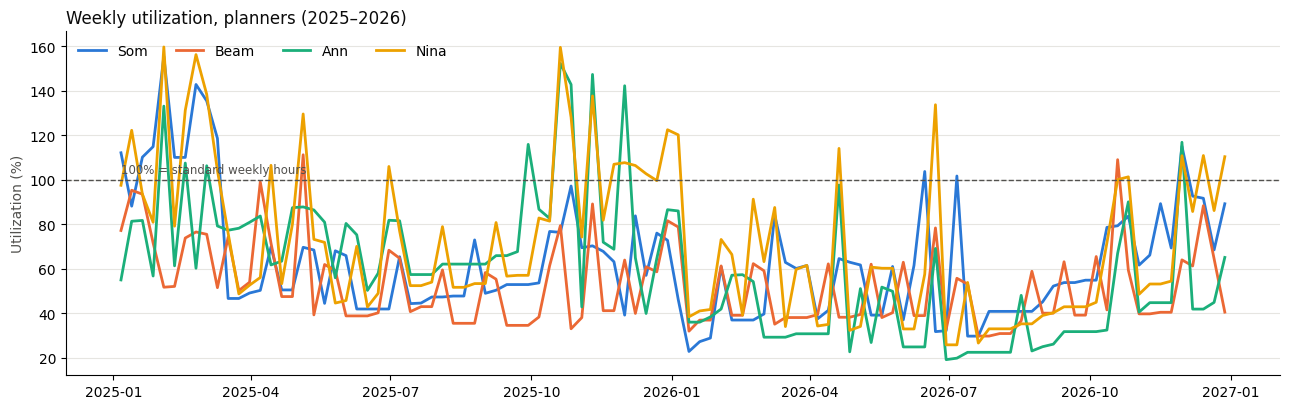

In [14]:
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
fig, ax = plt.subplots(figsize=(13, 4.2))
for (key, color) in zip([ekey[1], ekey[2], ekey[3], ekey[4]], [BLUE, ORANGE, AQUA, YELLOW]):
    d_ = planners[planners.EmployeeKey == key]
    ax.plot(d_.Week, d_.UtilizationRate * 100, color=color, lw=2, label=emp_name[key])
ax.axhline(100, color=INK2, lw=1, ls="--"); ax.text(planners.Week.min(), 103, "100% = standard weekly hours", color=INK2, fontsize=8.5)
ax.set_ylabel("Utilization (%)", color=INK2)
ax.set_title("Weekly utilization, planners (2025–2026)", loc="left", fontsize=12, color=INK)
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", lw=0.8); ax.legend(frameon=False, ncol=4, loc="upper left")
plt.tight_layout(); plt.savefig("p1_weekly_utilization.png", dpi=150); plt.show()

### Problem 2: inquiry and conversion

In [15]:
fi = fact_inquiry
kpi_funnel_by_channel = (fi.groupby("ChannelName")
    .agg(Inquiries=("InquiryCount", "sum"), Consulted=("IsConsulted", "sum"), Quoted=("IsQuoted", "sum"),
         Booked=("IsConverted", "sum"), Open=("IsOpen", "sum"))
    .assign(ConversionRate=lambda x: (x.Booked / x.Inquiries).round(3)).sort_values("Inquiries", ascending=False))
kpi_response_vs_conversion = (fi.groupby("ResponseTimeBand")
    .agg(Inquiries=("InquiryCount", "sum"), ConsultRate=("IsConsulted", "mean"), ConversionRate=("IsConverted", "mean")).round(3)
    .reindex(["<1h", "1-24h", ">24h", "Not logged", "In person"]).dropna())
kpi_lost_reasons = (fi[fi.IsLost == 1].groupby(["ClosedBy", "LostReason"]).size().rename("Lost").reset_index()
                    .assign(Share=lambda x: (x.Lost / x.Lost.sum()).round(3)).sort_values("Lost", ascending=False))
q = fi[fi.IsQuoted == 1].assign(Outcome=lambda x: np.select([x.IsConverted == 1, x.LostReason == "Price"], ["Booked", "Lost on price"], "Other"))
kpi_quote_share = q.groupby("Outcome")["QuoteShareOfBudget"].agg(["count", "median", "mean"]).round(3)
kpi_by_package = (fi.merge(dim_package[["PackageKey", "PackageFamily"]], left_on="IndicativePackageKey", right_on="PackageKey")
                  .groupby("PackageFamily").agg(Inquiries=("InquiryCount", "sum"), ConversionRate=("IsConverted", "mean")).round(3))
display(kpi_funnel_by_channel); display(kpi_response_vs_conversion); display(kpi_lost_reasons); display(kpi_quote_share); display(kpi_by_package)

,Inquiries,Consulted,Quoted,Booked,Open,ConversionRate
ChannelName,,,,,,
Wedding Fair,516,244,190,56,0,0.109
LINE OA,442,246,187,63,5,0.143
Facebook,305,161,122,45,2,0.148
TikTok,190,78,49,4,6,0.021
Referral,170,111,85,43,4,0.253
Instagram,166,79,62,34,2,0.205
Website,65,36,29,7,0,0.108
Walk-in,51,37,29,10,1,0.196


,Inquiries,ConsultRate,ConversionRate
ResponseTimeBand,,,
<1h,622,0.571,0.148
1-24h,946,0.483,0.134
>24h,29,0.862,0.138
Not logged,17,0.000,0.000
In person,291,0.533,0.134


,ClosedBy,LostReason,Lost,Share
0,AutoRule,No reply,1220,0.757
4,Sales,Price,127,0.079
3,Sales,Date unavailable,109,0.068
2,Sales,Chose competitor,81,0.050
1,Sales,Budget changed,40,0.025
5,Sales,Scope mismatch,35,0.022


,count,median,mean
Outcome,,,
Booked,262,0.130,0.136
Lost on price,87,0.174,0.178
Other,404,0.131,0.139


,Inquiries,ConversionRate
PackageFamily,,
Custom,109,0.073
Day-of Coordination,302,0.179
Full Planning,626,0.181
Partial Planning,348,0.144
Unknown,520,0.071


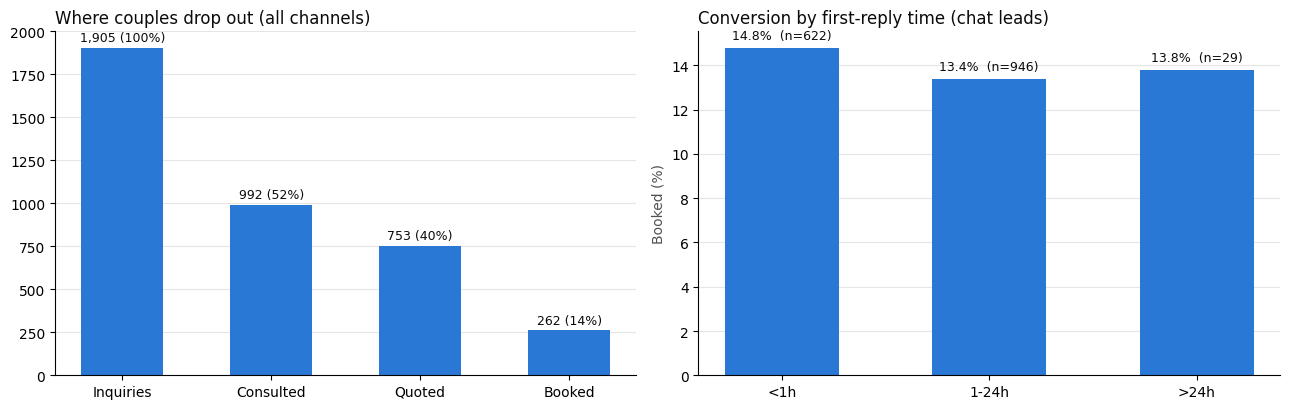

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
stages = ["Inquiries", "Consulted", "Quoted", "Booked"]
tot_stage = kpi_funnel_by_channel[stages].sum()
axes[0].bar(stages, tot_stage.values, color=BLUE, width=0.55)
for x_, v in enumerate(tot_stage.values):
    axes[0].text(x_, v + tot_stage.max() * 0.02, f"{v:,} ({v / tot_stage.iloc[0]:.0%})", ha="center", fontsize=9, color=INK)
axes[0].set_title("Where couples drop out (all channels)", loc="left", fontsize=12, color=INK)
rv = kpi_response_vs_conversion.loc[[b for b in ["<1h", "1-24h", ">24h"] if b in kpi_response_vs_conversion.index]]
axes[1].bar(rv.index, rv.ConversionRate * 100, color=BLUE, width=0.55)
for x_, (v, n_) in enumerate(zip(rv.ConversionRate * 100, rv.Inquiries)):
    axes[1].text(x_, v + 0.4, f"{v:.1f}%  (n={int(n_)})", ha="center", fontsize=9, color=INK)
axes[1].set_title("Conversion by first-reply time (chat leads)", loc="left", fontsize=12, color=INK)
axes[1].set_ylabel("Booked (%)", color=INK2)
for a in axes:
    for sp in ["top", "right"]: a.spines[sp].set_visible(False)
    a.grid(axis="y", color="#e6e5e1", lw=0.8); a.set_axisbelow(True)
plt.tight_layout(); plt.savefig("p2_funnel_response.png", dpi=150); plt.show()

for n, df in {"kpi_peak_weeks": kpi_peak_weeks, "kpi_monthly_demand": kpi_monthly_demand, "kpi_peak_acceptance": kpi_peak_acceptance,
              "kpi_funnel_by_channel": kpi_funnel_by_channel, "kpi_response_vs_conversion": kpi_response_vs_conversion,
              "kpi_lost_reasons": kpi_lost_reasons, "kpi_quote_share": kpi_quote_share, "kpi_by_package": kpi_by_package}.items():
    df.to_csv(ROOT / "gold" / f"{n}.csv")

## 9. From numbers to decisions

| Who / when | Looks at | Typical finding | Decision |
|---|---|---|---|
| Ops lead, Monday meeting | `kpi_peak_weeks`, FactEmployeeWeeklyWorkload for the next 8 weeks | A lead planner is at 109% in the week of 14 Feb | Move one wedding to the least-loaded planner, or book a freelancer. Then check that the freelancer isn't now over **their** (lower) hours. |
| Ops + HR, each quarter | Weekly utilization by month, `kpi_monthly_demand` | October–February averages 59–82% across ops staff, with 30 single weeks above 130%; Jul–Sep (Buddhist Lent) sit around 30–39% | Hire freelancers for the peak instead of permanent staff; schedule leave in the low season |
| Sales + management | `kpi_peak_acceptance`, `Date unavailable` losses by requested month | Couples asking for auspicious peak dates are turned away | Cap peak-date bookings per lead planner, or charge a peak-date premium |
| Sales manager, weekly | `kpi_response_vs_conversion` | Leads answered within an hour book more often than night leads answered next morning | Add an evening inbox shift (20:00–23:00) and track the "<1h" share |
| Sales manager | `kpi_funnel_by_channel` | Fair leads consult often but book less; referrals book best | Follow up fair leads within 48 h; ask booked couples for referrals |
| Sales + management | `kpi_quote_share`, `kpi_lost_reasons` | Couples lost on price were quoted a bigger share of their budget | Offer Partial Planning when the Full fee goes above about 15% of the couple's budget |
| Sales manager | `kpi_lost_reasons` by ClosedBy | Most losses are "No reply" (AutoRule), not a stated reason | Add a day-7 and day-21 follow-up before the 30-day rule fires |

The data does not prove that a faster reply *causes* bookings. Couples who write late at
night may simply be less ready to book. Treat it as a reason to test an evening shift and
then compare, not as proof.

## 10. Lineage and the cross-check with the SQL warehouse

In [17]:
lineage = pd.DataFrame([
    ("Bronze → Silver", "chat_webhook_events", "chat_messages", "Drop re-delivered events, UTC→Bangkok, parse #CODE / ad ID, drop text"),
    ("Bronze → Silver", "inbox_send_log + crm_Employee", "chat_messages", "Staff code → EmployeeID; Bot kept but flagged"),
    ("Bronze → Silver", "crm_CustomerChannelAccount", "chat_messages", "Platform user ID → customer and inquiry"),
    ("Bronze → Silver", "kiosk_form", "kiosk_leads", "Drop retried syncs, normalise and hash phone, check each reached the CRM"),
    ("Bronze → Silver", "crm_Inquiry + crm_Event + chat_messages", "inquiries", "Response time and first responder (bot ignored), furthest stage, quote share of budget"),
    ("Bronze → Silver", "crm_EventEmployeeAssignment + crm_Event", "staff_assignments, staff_hours_weekly", "≤12 h wedding-day, rest spread from assignment week"),
    ("Bronze → Silver", "auspicious_calendar", "calendar", "One row per date, highest level"),
    ("Silver → Gold", "calendar", "DimDate", "Add high season, Lent, auspicious flags"),
    ("Silver → Gold", "crm_Package / crm_Employee + Role", "DimPackage / DimEmployee", "Surrogate key, Unknown = -1"),
    ("Silver → Gold", "inquiries", "FactInquiry", "Stage flags, durations, response band"),
    ("Silver → Gold", "staff_assignments + crm_Event", "FactEventBooking", "Staff count and hours per wedding"),
    ("Silver → Gold", "staff_hours_weekly + crm_Employee", "FactEmployeeWeeklyWorkload", "Employee × week grid incl. zero weeks; utilization, overtime"),
    ("Gold → Consumption", "Facts + dims", "kpi_* views", "Section 8"),
], columns=["Flow", "Source", "Target", "Transformation"])
display(lineage)

# Export the CRM tables + chat messages in OLTP v4 shape, so the SQL ETL can be run on exactly this data.
snap = ROOT / "oltp_snapshot"
for t, df in crm.items():
    df.to_csv(snap / f"{t}.csv", index=False)
silver_chat.to_csv(snap / "ChatMessage.csv", index=False)
auspicious.to_csv(snap / "AuspiciousDate.csv", index=False)
print("OLTP snapshot written to", snap)

,Flow,Source,Target,Transformation
0,Bronze → Silver,chat_webhook_events,chat_messages,"Drop re-delivered events, UTC→Bangkok, parse #..."
1,Bronze → Silver,inbox_send_log + crm_Employee,chat_messages,Staff code → EmployeeID; Bot kept but flagged
2,Bronze → Silver,crm_CustomerChannelAccount,chat_messages,Platform user ID → customer and inquiry
3,Bronze → Silver,kiosk_form,kiosk_leads,"Drop retried syncs, normalise and hash phone, ..."
4,Bronze → Silver,crm_Inquiry + crm_Event + chat_messages,inquiries,Response time and first responder (bot ignored...
5,Bronze → Silver,crm_EventEmployeeAssignment + crm_Event,"staff_assignments, staff_hours_weekly","≤12 h wedding-day, rest spread from assignment..."
6,Bronze → Silver,auspicious_calendar,calendar,"One row per date, highest level"
7,Silver → Gold,calendar,DimDate,"Add high season, Lent, auspicious flags"
8,Silver → Gold,crm_Package / crm_Employee + Role,DimPackage / DimEmployee,"Surrogate key, Unknown = -1"
9,Silver → Gold,inquiries,FactInquiry,"Stage flags, durations, response band"


OLTP snapshot written to zones_v3/oltp_snapshot


**Cross-check.** The files in `zones_v3/oltp_snapshot/` were loaded into PostgreSQL
(OLTP v4 lean schema) and `WeddingOrganizer_DW_v6_lean_ETL.sql` was run with
`asof = 2027-01-15`. Every row and every measure of FactInquiry, FactEventBooking and
FactEmployeeWeeklyWorkload matched the Gold CSVs above (first run on one simulated year: 29,257 values,
0 differences). The current pipeline (DW v7) repeats the check on all three years in
`tests/test_source_to_target.py`: 76,770 values compared, 0 differences.
A planted 0.5-hour error in one weekly row was caught. So the lake (pandas) and the
warehouse (SQL) apply the same business rules. The check script is
`crosscheck_v3.py` in the project files.

## 11. Storage summary

In [18]:
rows = []
for z in ["bronze", "silver", "gold"]:
    for f in sorted((ROOT / z).rglob("*.*")):
        rows.append({"zone": z, "file": str(f.relative_to(ROOT)), "rows": sum(1 for _ in open(f, encoding="utf-8")) - (0 if f.suffix == ".jsonl" else 1)})
storage = pd.DataFrame(rows)
display(storage.groupby("zone")["rows"].agg(["count", "sum"]).rename(columns={"count": "files", "sum": "rows"}))

,files,rows
zone,,
bronze,12,28352
gold,14,6902
silver,7,44853


## 12. Wrap-up

**KPI → where it is computed**

| KPI (capstone §2.1) | Gold table / view |
|---|---|
| Workload hours, utilization, overtime | FactEmployeeWeeklyWorkload, `kpi_peak_weeks` |
| Concurrent events vs. limit | FactEmployeeWeeklyWorkload.ActiveEvents, IsOverCapacity |
| Peak-period acceptance rate | FactInquiry × DimDate (requested date), `kpi_peak_acceptance` |
| Staff hours per wedding, by complexity and package | FactEventBooking |
| Conversion rate, by channel, by package | FactInquiry, `kpi_funnel_by_channel`, `kpi_by_package` |
| Response time | FactInquiry.ResponseTimeMinutes / ResponseTimeBand, `kpi_response_vs_conversion` |
| Sales-cycle days, stage drop-off | FactInquiry stage flags and day counts |
| Lost-reason share (by who closed it) | FactInquiry, `kpi_lost_reasons` |
| Quote vs. budget | FactInquiry.QuoteShareOfBudget, `kpi_quote_share` |

**Deliberate simplifications**

- One open inquiry per chat account. In the real CRM, sales links a returning couple's
  new messages to the right inquiry.
- Response time is clock time, including nights. A business-hours version is a later add-on.
- The notebook builds Gold in one run. The SQL load keeps past weeks of
  FactEmployeeWeeklyWorkload frozen and only rebuilds from the current week, so last
  month's utilization report never changes after the fact.
- Storage is CSV / JSON on local disk. The zone boundaries and rules carry over unchanged
  to object storage plus a warehouse.